# Serie II, inciso 4: anomalías y reglas propuestas

Pregunta: ¿qué observaciones multivariables merecen revisión y cómo convertirlas en avisos comprensibles para el jefe de calderas? Se aplica **un Isolation Forest**, se revisan sus aciertos aparentes y omisiones, y se simulan reglas de persistencia. No se diagnostican fallas ni se construye infraestructura de notificaciones. La campeona de quince variables permanece intacta.

Se conservan las 86,400 filas cada cinco segundos: reducir a diez segundos puede perder picos aislados. Las treinta mediciones actuales son entradas; fecha e identificadores no. El caudal participa como una medición más, sin etiqueta supervisada. Este detector es independiente de Ridge. Los treinta faltantes se imputan con medianas del entrenamiento únicamente para calcular el score y se marcan por separado; ninguna fila se excluye.

Primeros cuatro bloques de 24 h: ajuste y referencia de cuantiles. Quinto bloque: reproducción descriptiva con modelo congelado, **ya observado anteriormente, no test independiente**. No hay etiquetas de salud ni fallas: calibrar sobre el histórico tampoco lo convierte en funcionamiento sano.

Se usa el último régimen cuyo minuto ya cerró, nunca el del minuto en curso. Los primeros doce registros no tienen ese contexto y usan umbral global. Los regímenes y el detector se aprendieron con los primeros cuatro días; la causalidad de la reproducción con parámetros congelados corresponde al quinto. No se afirma despliegue prospectivo durante el ajuste.

Referencia del algoritmo: [documentación oficial de IsolationForest, scikit-learn 1.6](https://scikit-learn.org/1.6/modules/generated/sklearn.ensemble.IsolationForest.html). `-score_samples` crece con rareza; no se usa `predict` ni su umbral automático. No requiere estandarización; seis presiones correlacionadas pueden dar más representación a esa familia. Seis tags concordantes no son seis confirmaciones independientes.

In [1]:
from pathlib import Path
import sys, json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display

RAIZ = Path.cwd() if (Path.cwd()/"scripts").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ))
from scripts.anomalias_serie2 import (crear_detector, contexto_cerrado,
    umbrales_por_contexto, simular_aviso, episodios_marcados)
SALIDA = RAIZ/"outputs/anomalias"
SALIDA.mkdir(parents=True, exist_ok=True)
protegidos = list((RAIZ/"outputs").glob("serie2_*")) + [
    RAIZ/"data/raw/serie2/data.csv", RAIZ/"notebooks/07_sensor_virtual_serie2.ipynb",
    RAIZ/"scripts/modelado_serie2.py", RAIZ/"outputs/regimenes/modelo_regimenes.joblib",
    RAIZ/"outputs/regimenes/asignaciones_minuto.csv", RAIZ/"notebooks/09_regimenes_operacion_serie2.ipynb"]
huellas = {str(p.relative_to(RAIZ)): hashlib.sha256(p.read_bytes()).hexdigest()
           for p in protegidos if p.is_file()}
datos = pd.read_csv(RAIZ/"data/raw/serie2/data.csv", parse_dates=["date"])
assert len(datos)==86400 and datos.date.diff().dropna().eq(pd.Timedelta(seconds=5)).all()
x = datos.drop(columns="date")
assert x.shape[1]==30 and not np.isinf(x.to_numpy()).any()
corte = datos.date.iloc[0]+pd.Timedelta(days=4)
ajuste = datos.date.lt(corte)
referencias = pd.read_csv(RAIZ/"outputs/regimenes/asignaciones_minuto.csv", parse_dates=["disponible_desde"])
contexto = contexto_cerrado(datos.date, referencias)
assert (contexto.disponible_desde.dropna() <= datos.date[contexto.disponible_desde.notna()]).all()
assert contexto.regimen_cerrado.eq(0).sum()==12
detector = crear_detector().fit(x.loc[ajuste])
score = -detector.score_samples(x)
umbrales = umbrales_por_contexto(score[ajuste], contexto.regimen_cerrado[ajuste])
filas = pd.DataFrame({"fila_fuente": np.arange(len(datos)), "date": datos.date,
    "fase": np.where(ajuste, "ajuste_referencia", "reproduccion_dia5"),
    "regimen_cerrado": contexto.regimen_cerrado, "contexto_disponible_desde": contexto.disponible_desde,
    "score": score, "umbral": contexto.regimen_cerrado.map(umbrales),
    "faltantes": x.isna().sum(axis=1), "tags_faltantes": x.isna().apply(lambda f: ";".join(f.index[f]), axis=1)})
filas["candidata"] = filas.score.gt(filas.umbral)
filas["aviso_multivariable"] = simular_aviso(filas.candidata).activo
temperatura = datos["TE_8332A.AV_0#"]
filas["fuera_banda_temperatura"] = temperatura.lt(530) | temperatura.gt(545)
filas["aviso_temperatura"] = simular_aviso(filas.fuera_banda_temperatura, requeridas=12, ventana=12).activo
filas["aviso_calidad"] = filas.faltantes.gt(0)
display(filas.groupby("fase")[["candidata", "aviso_multivariable", "fuera_banda_temperatura", "aviso_temperatura", "aviso_calidad"]].agg(["sum", "mean"]))
print("Umbrales de referencia:", umbrales)

candidata           aviso_multivariable            \
                        sum      mean                 sum      mean   
fase                                                                  
ajuste_referencia       692  0.010012                1084  0.015683   
reproduccion_dia5       227  0.013137                 307  0.017766   

                  fuera_banda_temperatura           aviso_temperatura  \
                                      sum      mean               sum   
fase                                                                    
ajuste_referencia                    5939  0.085923              5921   
reproduccion_dia5                    1098  0.063542              1110   

                            aviso_calidad            
                       mean           sum      mean  
fase                                                 
ajuste_referencia  0.085663            30  0.000434  
reproduccion_dia5  0.064236             0  0.000000

Umbrales de referencia: {0: 0.5312032903232298, 1: 0.5204406660545522, 2: 0.5481637414864025}


## Reglas propuestas y carga de revisión

1. **Calidad:** avisar desde el primer dato ausente; cerrar cuando vuelve. No prueba sensor averiado: puede ser adquisición o comunicación. No interpretar el valor imputado como medición recuperada.
2. **Anomalía multivariable:** score superior al percentil 99 del contexto, con tres candidatas entre las últimas seis lecturas y candidata actual. Se requieren seis lecturas de historia; seis muestras representan 30 s de cobertura nominal (25 s entre extremos). Cerrar tras doce lecturas consecutivas sin candidatura, aproximadamente un minuto. El estado activo incluye esa espera de recuperación.
3. **Temperatura final:** doce lecturas consecutivas fuera de 530–545 °C; cerrar con doce dentro. Es una referencia de operación normal de la publicación, **no límite de seguridad del fabricante** ni etiqueta de falla. Requiere aprobación de operación antes de uso real.

Percentil y persistencia son decisiones provisionales para administrar revisión, no estimaciones de tasa de falsas alarmas. Son avisos de desviación presente; no hay evidencia de anticipación a una falla futura. No se automatiza parada, ajuste ni envío. La sensibilidad 98/99/99.5 y una segunda semilla describen fragilidad/carga sin escoger el resultado más atractivo.

In [2]:
episodios = []
for tipo, columna in [("candidata", "candidata"), ("multivariable", "aviso_multivariable"),
                      ("temperatura", "aviso_temperatura"), ("calidad", "aviso_calidad")]:
    e = episodios_marcados(datos.date, filas[columna])
    e["tipo"] = tipo
    episodios.append(e)
episodios = pd.concat(episodios, ignore_index=True)
# Los episodios se simulan una sola vez: no se reinician artificialmente al cambiar de día.
resumen = episodios.groupby("tipo").agg(episodios=("inicio", "size"),
    cobertura_min=("cobertura_s", lambda s: s.sum()/60),
    mediana_cobertura_s=("cobertura_s", "median"), maxima_cobertura_s=("cobertura_s", "max"))
sensibilidad = []
for q in [.98, .99, .995]:
    u = umbrales_por_contexto(score[ajuste], contexto.regimen_cerrado[ajuste], q)
    candidata = filas.score.gt(contexto.regimen_cerrado.map(u))
    aviso = simular_aviso(candidata)
    for fase, mascara in [("ajuste_referencia", ajuste), ("reproduccion_dia5", ~ajuste)]:
        sensibilidad.append({"cuantil": q, "fase": fase, "lecturas": int(mascara.sum()),
            "candidatas": int(candidata[mascara].sum()),
            "inicios_aviso": int(aviso.inicio_aviso[mascara].sum()),
            "minutos_activos": float(aviso.activo[mascara].sum()*5/60)})
sensibilidad = pd.DataFrame(sensibilidad)
alterno = crear_detector(43).fit(x.loc[ajuste])
score_alterno = -alterno.score_samples(x)
u_alterno = umbrales_por_contexto(score_alterno[ajuste], contexto.regimen_cerrado[ajuste])
candidata_alterna = score_alterno > contexto.regimen_cerrado.map(u_alterno)
jaccard = float((candidata_alterna & filas.candidata).sum()/(candidata_alterna | filas.candidata).sum())
display(resumen, sensibilidad)
print("Jaccard de candidaturas con semilla 43:", round(jaccard, 4))

,episodios,cobertura_min,mediana_cobertura_s,maxima_cobertura_s
tipo,,,,
calidad,2,2.500000,75.0,140
candidata,164,76.583333,5.0,520
multivariable,28,115.916667,205.0,815
temperatura,85,585.916667,330.0,1475


,cuantil,fase,lecturas,candidatas,inicios_aviso,minutos_activos
0,0.980,ajuste_referencia,69120,1383,42,171.416667
1,0.980,reproduccion_dia5,17280,730,18,86.166667
2,0.990,ajuste_referencia,69120,692,23,90.333333
3,0.990,reproduccion_dia5,17280,227,5,25.583333
4,0.995,ajuste_referencia,69120,346,14,45.666667
5,0.995,reproduccion_dia5,17280,42,3,5.583333


Jaccard de candidaturas con semilla 43: 0.7515


## Revisión de episodios y omisiones

Se revisan cuatro extremos ya documentados en el EDA y el score máximo, sin retocar el detector para capturarlos. La mediana de los cinco minutos **anteriores** ayuda a distinguir pico de elevación previa. También se muestran las tres mayores desviaciones absolutas respecto de mediana/MAD de los primeros cuatro días del contexto cerrado. Esto es explicación descriptiva, no atribución del Isolation Forest ni causalidad. La ventana futura del gráfico es solo inspección retrospectiva; nunca entra en score, contexto ni reglas.

,caso,date,tag,valor,mediana_5min_anteriores,regimen_cerrado,score,umbral,candidata,aviso_activo,tags_desviacion_descriptiva
0,Máximo score,2022-03-30 12:25:04,PT_8313A.AV_0#,-442.73,-184.830,2,0.671226,0.548164,True,True,PT_8313E.AV_0#;PT_8313D.AV_0#;PT_8313C.AV_0#
1,Presiones del hogar,2022-03-28 14:08:09,PT_8313A.AV_0#,-449.61,-222.725,2,0.616825,0.548164,True,True,PT_8313E.AV_0#;PT_8313D.AV_0#;PT_8313F.AV_0#
2,Vibración B,2022-03-30 07:47:09,YFJ3_ZD2.AV_0#,24.96,11.270,1,0.530878,0.520441,True,True,YFJ3_ZD2.AV_0#;YFJ3_ZD1.AV_0#;YFJ3_AI.AV_0#
3,Pico de corriente,2022-03-29 14:06:59,YFJ3_AI.AV_0#,51.28,22.070,2,0.470975,0.548164,False,False,YFJ3_AI.AV_0#;YFJ3_ZD1.AV_0#;YFJ3_ZD2.AV_0#
4,Caída de retornos,2022-03-30 08:53:09,FT_8306A.AV_0#,262.49,720.920,1,0.424448,0.520441,False,False,FT_8306A.AV_0#;FT_8306B.AV_0#;AIR_8301B.AV_0#


,caso,date,tag,valor,mediana_5min_anteriores
0,Máximo score,2022-03-30 12:25:04,PT_8313A.AV_0#,-442.73,-184.830
1,Máximo score,2022-03-30 12:25:04,PT_8313B.AV_0#,-527.58,-229.690
2,Máximo score,2022-03-30 12:25:04,PT_8313C.AV_0#,-487.88,-191.420
3,Máximo score,2022-03-30 12:25:04,PT_8313D.AV_0#,-478.99,-154.830
4,Máximo score,2022-03-30 12:25:04,PT_8313E.AV_0#,-559.98,-208.415
5,Máximo score,2022-03-30 12:25:04,PT_8313F.AV_0#,-528.42,-192.725
6,Presiones del hogar,2022-03-28 14:08:09,PT_8313A.AV_0#,-449.61,-222.725
7,Presiones del hogar,2022-03-28 14:08:09,PT_8313B.AV_0#,-530.18,-277.195
8,Presiones del hogar,2022-03-28 14:08:09,PT_8313C.AV_0#,-496.70,-245.385
9,Presiones del hogar,2022-03-28 14:08:09,PT_8313D.AV_0#,-499.13,-216.555


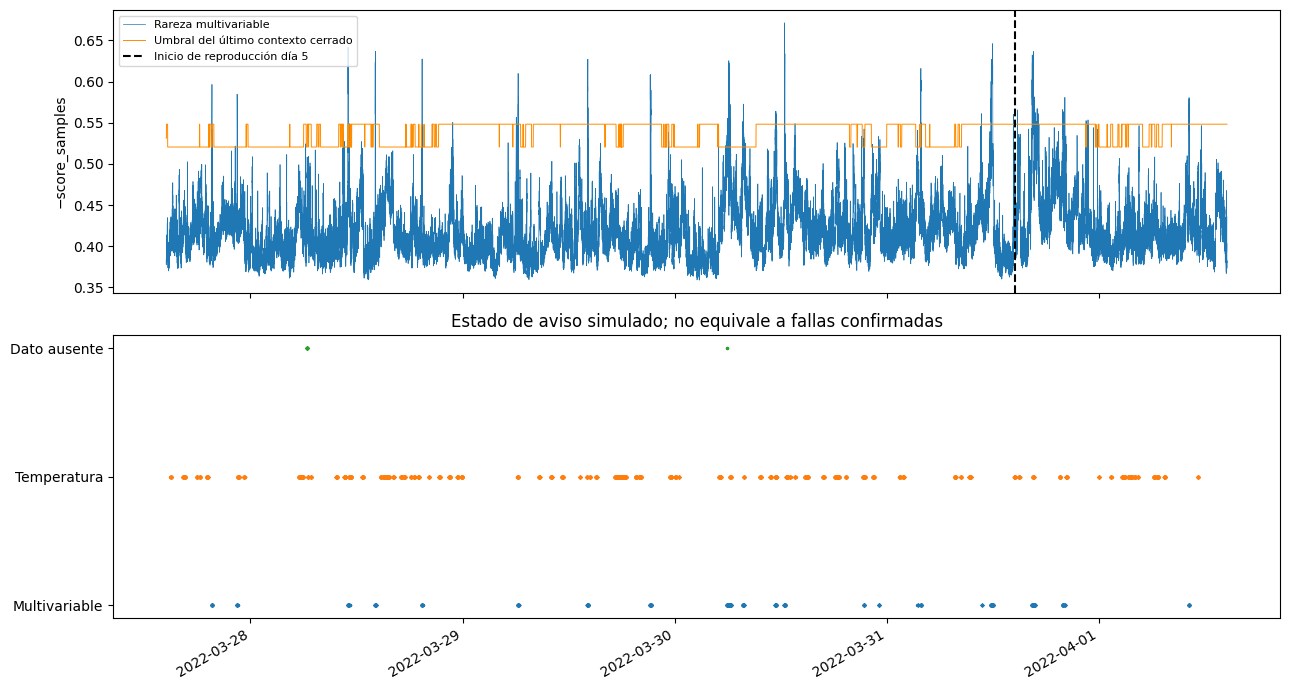

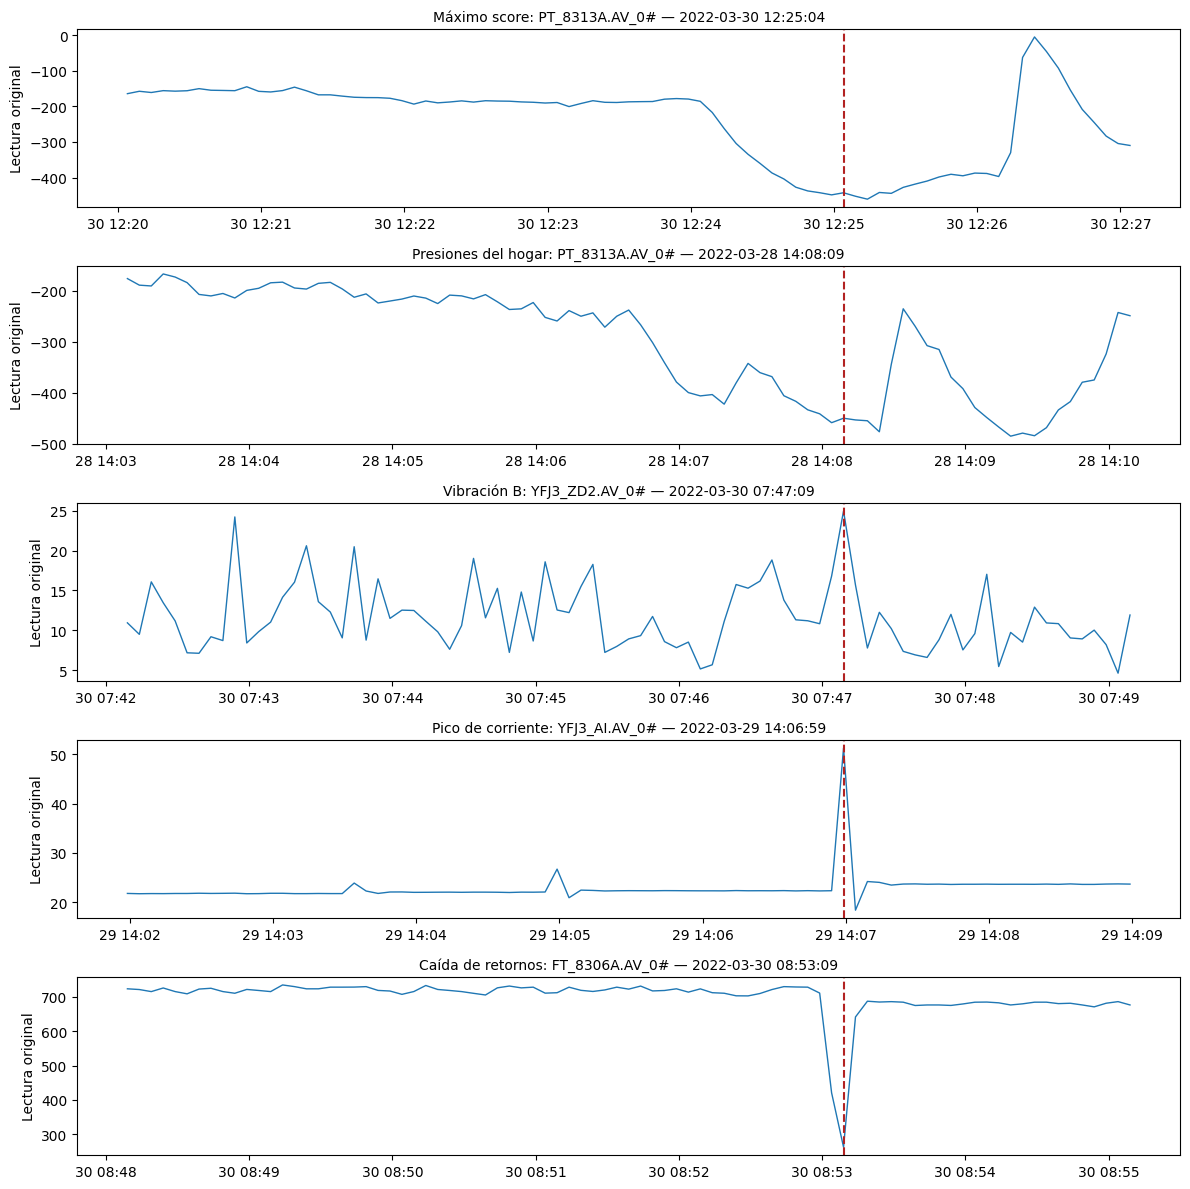

In [3]:
casos_definidos = [
    ("Máximo score", datos.date.iloc[int(np.argmax(score))], "PT_8313A.AV_0#"),
    ("Presiones del hogar", pd.Timestamp("2022-03-28 14:08:09"), "PT_8313A.AV_0#"),
    ("Vibración B", pd.Timestamp("2022-03-30 07:47:09"), "YFJ3_ZD2.AV_0#"),
    ("Pico de corriente", pd.Timestamp("2022-03-29 14:06:59"), "YFJ3_AI.AV_0#"),
    ("Caída de retornos", pd.Timestamp("2022-03-30 08:53:09"), "FT_8306A.AV_0#")]
casos = []
for nombre, fecha, tag in casos_definidos:
    i = datos.index[datos.date.eq(fecha)][0]
    perfil = int(contexto.regimen_cerrado.iloc[i])
    base = x.loc[ajuste & contexto.regimen_cerrado.eq(perfil)]
    mediana = base.median()
    mad = (base-mediana).abs().median().replace(0, np.nan)
    desviaciones = ((x.iloc[i]-mediana)/(1.4826*mad)).abs().sort_values(ascending=False)
    previo = datos.date.ge(fecha-pd.Timedelta(minutes=5)) & datos.date.lt(fecha)
    casos.append({"caso": nombre, "date": fecha, "tag": tag, "valor": float(x.loc[i, tag]),
        "mediana_5min_anteriores": float(x.loc[previo, tag].median()),
        "regimen_cerrado": perfil, "score": float(score[i]), "umbral": float(filas.umbral.iloc[i]),
        "candidata": bool(filas.candidata.iloc[i]), "aviso_activo": bool(filas.aviso_multivariable.iloc[i]),
        "tags_desviacion_descriptiva": ";".join(desviaciones.head(3).index)})
casos = pd.DataFrame(casos)
contrastes = []
for nombre, fecha, tag in casos_definidos:
    tags = ([f"PT_8313{letra}.AV_0#" for letra in "ABCDEF"] if "score" in nombre or "Presiones" in nombre
            else (["FT_8306A.AV_0#", "FT_8306B.AV_0#"] if "retornos" in nombre
                  else ["YFJ3_ZD1.AV_0#", "YFJ3_ZD2.AV_0#", "YFJ3_AI.AV_0#"]))
    previo = datos.date.ge(fecha-pd.Timedelta(minutes=5)) & datos.date.lt(fecha)
    for senal in tags:
        contrastes.append({"caso": nombre, "date": fecha, "tag": senal,
            "valor": float(x.loc[datos.date.eq(fecha), senal].iloc[0]),
            "mediana_5min_anteriores": float(x.loc[previo, senal].median())})
contrastes = pd.DataFrame(contrastes)
display(casos, contrastes)
fig, axs = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
axs[0].plot(datos.date, score, lw=.5, label="Rareza multivariable")
axs[0].plot(datos.date, filas.umbral, lw=.7, color="darkorange", label="Umbral del último contexto cerrado")
axs[0].axvline(corte, color="black", ls="--", label="Inicio de reproducción día 5")
axs[0].set_ylabel("−score_samples"); axs[0].legend(fontsize=8, loc="upper left")
for j, (col, nombre) in enumerate([("aviso_multivariable", "Multivariable"), ("aviso_temperatura", "Temperatura"), ("aviso_calidad", "Dato ausente")]):
    t = datos.date[filas[col]]
    axs[1].scatter(t, np.full(len(t), j), s=2, label=nombre)
axs[1].set_yticks([0, 1, 2], ["Multivariable", "Temperatura", "Dato ausente"])
axs[1].set_title("Estado de aviso simulado; no equivale a fallas confirmadas")
fig.autofmt_xdate(); fig.tight_layout()
fig.savefig(SALIDA/"anomalias_tiempo.png", dpi=140); plt.show()
fig, axs = plt.subplots(5, 1, figsize=(12, 12))
for ax, (nombre, fecha, tag) in zip(axs, casos_definidos):
    ventana = datos.date.between(fecha-pd.Timedelta(minutes=5), fecha+pd.Timedelta(minutes=2))
    ax.plot(datos.date[ventana], x.loc[ventana, tag], lw=1)
    ax.axvline(fecha, color="firebrick", ls="--")
    ax.set_title(f"{nombre}: {tag} — {fecha}", fontsize=10)
    ax.set_ylabel("Lectura original")
fig.tight_layout(); fig.savefig(SALIDA/"casos_revision.png", dpi=140); plt.show()

## Hallazgos y límites de la elección

- 919 candidaturas en 164 tramos contiguos, convertidas en **28 episodios de aviso multivariable**, con 115.92 minutos activos incluyendo recuperación. En el quinto bloque hay 227 candidaturas y cinco inicios de aviso; no son cinco fallas. Ningún episodio multivariable cruza ese corte.
- Dos avisos de calidad: 30 lecturas ausentes, 2.5 minutos de cobertura, exclusivamente en el agua de atemperación. No se descarta ninguna fila.
- La banda térmica genera 85 episodios de aviso y 585.92 minutos activos. Sus 7,037 lecturas fuera de banda son distintas del tiempo activo porque la regla exige persistencia e incluye recuperación. La carga es considerable: revisar banda y tiempos con operación; no afirmar 85 fallas térmicas.
- Percentiles 98/99/99.5 dan respectivamente 60/28/17 inicios multivariables en cinco días. Es sensibilidad fuerte al umbral, no prueba de que 99 sea óptimo. El cambio de semilla da Jaccard 0.7515 en candidaturas; tampoco son invariantes al muestreo aleatorio.
- El máximo score, 30 de marzo a las 12:25:04, coincide con descenso de las seis presiones del hogar frente a sus medianas previas. `PT_8313A` pasa de mediana previa −184.83 a −442.73. Es coherencia de una familia: priorizar contraste físico y del DCS, sin concluir daño del equipo.
- En el pico de vibración B de 24.96 ya había mediana previa elevada de 11.27. Vibración A es 7.17 frente a 6.595 previa y corriente 20.18 frente a 20.15: no hay corroboración fuerte de corriente en ese instante. Se propone inspección, no diagnóstico mecánico.
- El pico de corriente 51.28 frente a mediana previa 22.07 y la caída de retorno A a 262.49 frente a 720.92 **quedan sin candidatura ni aviso multivariable**. La tabla cruzada conserva las otras señales para revisión. Se mantienen como limitaciones observadas, sin reajustar para encajar esos casos.

## Decisión para el jefe de calderas

**Priorizar verificación, sin diagnóstico automático.** Un cambio conjunto y persistente en presión, aire, temperatura o vibración amerita contrastar carga, mandos y registro del operador. Puede ser proceso/equipo, pero una perturbación compartida del DCS también produce coherencia entre señales. Las seis presiones del hogar son una familia correlacionada; verificar con instrumento independiente antes de tratarla como evidencia física redundante.

Un pico aislado, dato ausente o señal plana amerita revisar calidad de señal, alimentación/comunicación, calibración y respuesta frente a un instrumento o señal de mando independiente. El tramo constante de válvula del EDA no demuestra sensor congelado: puede ser un setpoint estable. Las dos interrupciones de agua prueban ausencia de datos, sin identificar su causa. Si hay riesgo operativo se aplica el procedimiento existente del ingenio y sus límites autorizados.

El pico de corriente de 51.28 y la caída simultánea de retornos **no superan el umbral del detector**: la rareza multivariable no sustituye límites por sensor o protecciones del fabricante. No se inventan esos límites porque faltan unidades/rangos y especificaciones. La banda térmica es complementaria; su coincidencia con el detector no mide precisión. No se presume qué evento ocurrió después ni se afirma que el aviso habría evitado una falla.

Impacto medible aquí: carga de revisión y duración de estados activos, no ahorro ni fallas evitadas. Certeza alta en las cuentas y ausencia de datos; moderada en la descripción de eventos; baja para causa, anticipación y desempeño futuro. Para validar: nuevos días congelando parámetros, bitácora de eventos/mantenimiento, estado de carga y mandos, unidades/calibración y confirmación independiente. Operación debe fijar límites y tiempos admisibles. Sin etiquetas no son calculables precisión, recall, falsas alarmas reales ni tiempo de anticipación.

Este notebook responde únicamente al inciso 4. Quedan fuera nuevas features supervisadas, oportunidades de eficiencia e infraestructura de alertas.

**Inferencia operativa:** el cambio concordante de seis presiones favorece revisar un fenómeno común de tiro/proceso o adquisición antes que seis averías independientes. El pico de corriente coincide con aumentos de ambas vibraciones y merece revisar un transitorio electromecánico. Los tags FT_8306A/B describen aire de cámaras de retorno, no condensado. Estas hipótesis ordenan la revisión y sus contrastes; no identifican daño ni reemplazan límites físicos con rareza multivariable.

La [interpretación física y decisiones de Serie II](../docs/conclusiones-serie-II.md#interpretación-física-y-decisiones) reúne evidencia, hipótesis alternativas y contrastes por inciso.

## Complemento del inciso 4: extremos individuales

Después de revisar las omisiones del detector, el usuario autorizó complementar la corriente y los dos retornos. Son tres señales elegidas **tras ver los casos**, por tanto esta comprobación es retrospectiva y no una validación independiente. Se mantiene Isolation Forest sin cambios; no se compara su score con esta escala ni se cambia su umbral.

Regla fijada antes de ejecutar este complemento: para cada señal y último régimen cerrado, calcular mediana y MAD (mediana de desviaciones absolutas) usando exclusivamente los cuatro días de referencia. Puntaje firmado = `(lectura − mediana)/(1.4826 × MAD)`. Los primeros doce registros usan referencia global. Los nueve MAD de estas tres señales/contextos deben ser positivos; si no, detener y revisar. Ausencias permanecen ausentes, sin imputación.

Se marca `|puntaje| > 6`, bilateralmente para todas las señales, sin adaptar límites a los valores de los dos casos. Es una regla conservadora provisional de distancia robusta, **no seis desviaciones estándar demostradas, probabilidad de falla ni límite físico**. El factor 1.4826 solo normaliza la escala MAD por una convención estadística; no presupone normalidad. Comparamos 4/6/8 para describir carga y sensibilidad, sin cambiar la elección seis después de mirar resultados.

Una marca instantánea se conserva aunque dure una sola lectura; se agrupan marcas consecutivas por sensor para revisión. Por separado se simula aviso sostenido con tres de seis lecturas, candidata actual y recuperación de doce. Un extremo aislado puede merecer revisión de señal sin generar aviso sostenido de operación. El histórico puede contener anomalías y la mediana por perfil no representa cada estado local: no llamar falsa alarma ni falla a las demás marcas.

La interpretación gerencial sigue siendo verificar: calidad/comunicación/calibración, señales relacionadas y registro del operador. No hay límites de fabricante ni unidades confirmadas para estas señales. El método no aprende transitorios locales ni demuestra anticipación. No se añaden otros sensores, modelos ni infraestructura.

,regimen_cerrado,tag,mediana,mad,escala_robusta,lecturas_referencia
0,0,YFJ3_AI.AV_0#,22.61,0.52,0.770952,69120
1,0,FT_8306A.AV_0#,715.20,11.51,17.064726,69120
2,0,FT_8306B.AV_0#,609.08,10.55,15.641430,69120
3,1,YFJ3_AI.AV_0#,22.18,0.42,0.622692,29508
4,1,FT_8306A.AV_0#,719.96,7.98,11.831148,29508
5,1,FT_8306B.AV_0#,605.68,6.85,10.155810,29508
6,2,YFJ3_AI.AV_0#,23.00,0.45,0.667170,39600
7,2,FT_8306A.AV_0#,709.19,17.42,25.826892,39600
8,2,FT_8306B.AV_0#,614.07,13.14,19.481364,39600


,tag,fase,lecturas_marcadas,episodios_instantaneos_iniciados,inicios_sostenidos,minutos_sostenidos,marcas_sin_candidatura_IF
0,YFJ3_AI.AV_0#,ajuste_referencia,308,300,0,0.000000,291
1,YFJ3_AI.AV_0#,reproduccion_dia5,183,84,2,10.083333,94
2,FT_8306A.AV_0#,ajuste_referencia,8,6,1,1.000000,8
3,FT_8306A.AV_0#,reproduccion_dia5,0,0,0,0.000000,0
4,FT_8306B.AV_0#,ajuste_referencia,3,2,1,1.000000,3
5,FT_8306B.AV_0#,reproduccion_dia5,6,5,0,0.000000,6


,tag,limite_robusto,lecturas_marcadas,episodios_instantaneos,inicios_sostenidos
0,YFJ3_AI.AV_0#,4,913,650,9
1,YFJ3_AI.AV_0#,6,491,384,2
2,YFJ3_AI.AV_0#,8,187,184,0
3,FT_8306A.AV_0#,4,2003,758,55
4,FT_8306A.AV_0#,6,8,6,1
5,FT_8306A.AV_0#,8,2,1,0
6,FT_8306B.AV_0#,4,1916,927,76
7,FT_8306B.AV_0#,6,9,7,1
8,FT_8306B.AV_0#,8,2,1,0


,date,tag,lectura,z_robusto,marca_instantanea,aviso_sostenido,candidata_IF,primer_aviso_en_30s,demora_desde_extremo_s
0,2022-03-29 14:06:59,YFJ3_AI.AV_0#,51.28,42.387997,True,False,False,NaT,NaN
1,2022-03-30 08:53:09,FT_8306A.AV_0#,262.49,-38.666577,True,False,False,2022-03-30 08:53:14,5.0
2,2022-03-30 08:53:09,FT_8306B.AV_0#,304.96,-29.610637,True,False,False,2022-03-30 08:53:19,10.0


Filas únicas con marca individual: 506
Filas únicas marcadas sin candidatura IF: 400


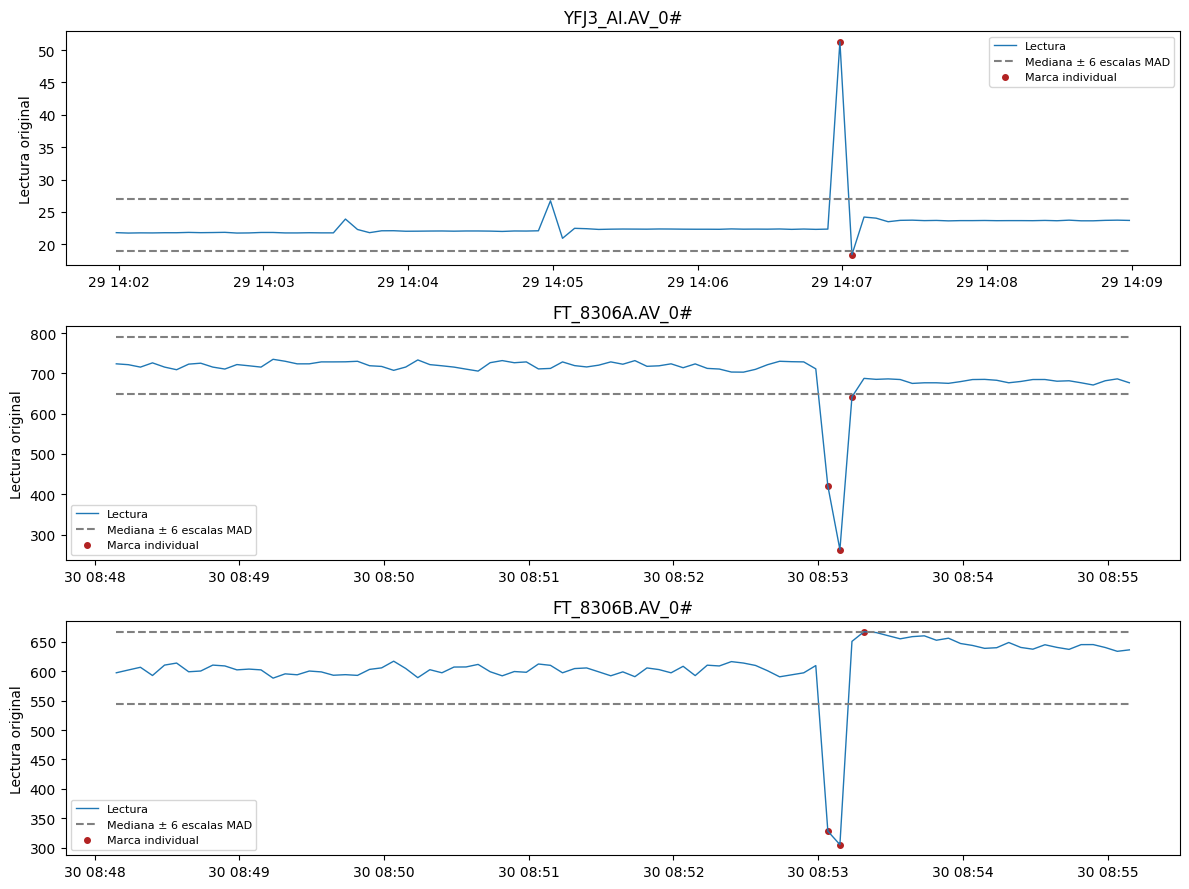

In [4]:
from scripts.anomalias_serie2 import referencias_robustas, puntajes_robustos

tags_extremos = ["YFJ3_AI.AV_0#", "FT_8306A.AV_0#", "FT_8306B.AV_0#"]
referencia_robusta = referencias_robustas(x.loc[ajuste, tags_extremos], contexto.regimen_cerrado[ajuste])
z_robusto = puntajes_robustos(x[tags_extremos], contexto.regimen_cerrado, referencia_robusta)
extremos = filas[["fila_fuente", "date", "fase", "regimen_cerrado"]].copy()
episodios_extremos, carga_extremos, sensibilidad_extremos = [], [], []
for tag in tags_extremos:
    marca = z_robusto[tag].abs().gt(6)
    aviso = simular_aviso(marca)
    extremos[f"z::{tag}"] = z_robusto[tag]
    extremos[f"marca::{tag}"] = marca
    extremos[f"sostenido::{tag}"] = aviso.activo
    for tipo, bandera in [("instantaneo", marca), ("sostenido", aviso.activo)]:
        e = episodios_marcados(datos.date, bandera)
        e["tag"], e["tipo"] = tag, tipo
        episodios_extremos.append(e)
    for fase, mascara in [("ajuste_referencia", ajuste), ("reproduccion_dia5", ~ajuste)]:
        inicios_marca = marca & ~marca.shift(fill_value=False)
        carga_extremos.append({"tag": tag, "fase": fase, "lecturas_marcadas": int(marca[mascara].sum()),
            "episodios_instantaneos_iniciados": int(inicios_marca[mascara].sum()),
            "inicios_sostenidos": int(aviso.inicio_aviso[mascara].sum()),
            "minutos_sostenidos": float(aviso.activo[mascara].sum()*5/60),
            "marcas_sin_candidatura_IF": int((marca & ~filas.candidata & mascara).sum())})
    for limite in [4, 6, 8]:
        marca_sensible = z_robusto[tag].abs().gt(limite)
        aviso_sensible = simular_aviso(marca_sensible)
        sensibilidad_extremos.append({"tag": tag, "limite_robusto": limite,
            "lecturas_marcadas": int(marca_sensible.sum()),
            "episodios_instantaneos": int((marca_sensible & ~marca_sensible.shift(fill_value=False)).sum()),
            "inicios_sostenidos": int(aviso_sensible.inicio_aviso.sum())})
episodios_extremos = pd.concat(episodios_extremos, ignore_index=True)
carga_extremos = pd.DataFrame(carga_extremos)
sensibilidad_extremos = pd.DataFrame(sensibilidad_extremos)
revision_extremos = []
for fecha, tags in [(pd.Timestamp("2022-03-29 14:06:59"), [tags_extremos[0]]),
                    (pd.Timestamp("2022-03-30 08:53:09"), tags_extremos[1:])]:
    i = datos.index[datos.date.eq(fecha)][0]
    for tag in tags:
        revision_extremos.append({"date": fecha, "tag": tag, "lectura": x.loc[i, tag],
            "z_robusto": z_robusto.loc[i, tag], "marca_instantanea": extremos.loc[i, f"marca::{tag}"],
            "aviso_sostenido": extremos.loc[i, f"sostenido::{tag}"],
            "candidata_IF": filas.candidata.iloc[i]})
        # Evaluación retrospectiva del aviso posterior, nunca entrada de la regla.
        posteriores = episodios_extremos.loc[episodios_extremos.tag.eq(tag)
            & episodios_extremos.tipo.eq("sostenido") & episodios_extremos.inicio.ge(fecha)
            & episodios_extremos.inicio.le(fecha+pd.Timedelta(seconds=30)), "inicio"]
        primero = posteriores.min()
        revision_extremos[-1]["primer_aviso_en_30s"] = primero
        revision_extremos[-1]["demora_desde_extremo_s"] = ((primero-fecha).total_seconds()
                                                            if pd.notna(primero) else np.nan)
revision_extremos = pd.DataFrame(revision_extremos)
display(referencia_robusta, carga_extremos, sensibilidad_extremos, revision_extremos)
marcas_cualquier_sensor = extremos[[f"marca::{tag}" for tag in tags_extremos]].any(axis=1)
print("Filas únicas con marca individual:", int(marcas_cualquier_sensor.sum()))
print("Filas únicas marcadas sin candidatura IF:", int((marcas_cualquier_sensor & ~filas.candidata).sum()))
fig, axs = plt.subplots(3, 1, figsize=(12, 9))
for ax, tag, fecha in zip(axs, tags_extremos,
        [pd.Timestamp("2022-03-29 14:06:59")]+[pd.Timestamp("2022-03-30 08:53:09")]*2):
    ventana = datos.date.between(fecha-pd.Timedelta(minutes=5), fecha+pd.Timedelta(minutes=2))
    r = referencia_robusta.loc[referencia_robusta.tag.eq(tag)].set_index("regimen_cerrado")
    centro = contexto.regimen_cerrado.map(r.mediana)
    escala = contexto.regimen_cerrado.map(r.escala_robusta)
    ax.plot(datos.date[ventana], x.loc[ventana, tag], label="Lectura", lw=1)
    ax.plot(datos.date[ventana], (centro+6*escala)[ventana], ls="--", color="gray", label="Mediana ± 6 escalas MAD")
    ax.plot(datos.date[ventana], (centro-6*escala)[ventana], ls="--", color="gray")
    marcada = ventana & extremos[f"marca::{tag}"]
    ax.scatter(datos.date[marcada], x.loc[marcada, tag], color="firebrick", s=16, label="Marca individual")
    ax.set_title(tag); ax.set_ylabel("Lectura original"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(SALIDA/"extremos_individuales.png", dpi=140); plt.show()
extremos.to_csv(SALIDA/"extremos_individuales.csv", index=False)
referencia_robusta.to_csv(SALIDA/"referencias_robustas.csv", index=False)
episodios_extremos.to_csv(SALIDA/"episodios_extremos.csv", index=False)
carga_extremos.to_csv(SALIDA/"carga_extremos.csv", index=False)
sensibilidad_extremos.to_csv(SALIDA/"sensibilidad_extremos.csv", index=False)
revision_extremos.to_csv(SALIDA/"revision_extremos.csv", index=False)
assert len(extremos)==len(datos) and z_robusto.isna().sum().sum()==x[tags_extremos].isna().sum().sum()


### Resultado del complemento y decisión

La regla fijada en seis escalas robustas marca los tres valores revisados: corriente 51.28 (puntaje +42.39), retorno A 262.49 (−38.67) y retorno B 304.96 (−29.61). Los tres carecían de candidatura de Isolation Forest. Es captura retrospectiva de extremos conocidos, **no tres fallas detectadas ni evidencia de precisión futura**.

En el mínimo de retornos aún no hay aviso sostenido: A lo activa a las 08:53:14, cinco segundos después; B a las 08:53:19, diez segundos después. Ambos pertenecen a una misma perturbación temporal y no son confirmaciones independientes. B combina dos marcas de caída con una de rebote alto: la regla reconoce desviaciones repetidas de cualquier signo, no un caudal persistentemente bajo. Estos tiempos miden reacción al extremo observado, **no anticipación a una falla**. El pico de corriente queda marcado sin activar aviso sostenido en los siguientes treinta segundos.

| Señal | Lecturas marcadas | Tramos de marcas | Avisos sostenidos |
|---|---:|---:|---:|
| Corriente | 491 | 384 | 2 |
| Retorno A | 8 | 6 | 1 |
| Retorno B | 9 | 7 | 1 |

Los 506 timestamps únicos con alguna marca incluyen 400 sin candidatura IF. No sumar las lecturas de los tres sensores como instantes distintos. La mediana de cobertura de tramos individuales es cinco segundos en los tres sensores. Los avisos sostenidos incluyen recuperación; los dos de retornos cubren un minuto cada uno aunque las marcas sean breves. En el quinto día hay dos inicios sostenidos de corriente, ninguno de retornos; no es prueba independiente.

La carga de corriente es importante: 384 tramos en cinco días, alrededor de 77 diarios como promedio del archivo, no una tasa futura estimada. Se recomienda **resumen de marcas para revisión de señales**; no enviar cada marca como alarma de equipo. El umbral es provisional y no convierte esta regla en una protección autorizada. Falta contrastar los picos con calidad de adquisición, instrumentos, mandos y eventos del operador.

Sensibilidad al bajar/subir el límite a 4/8: corriente 650/184 tramos y 9/0 avisos; retorno A 758/1 tramos y 55/0 avisos; retorno B 927/1 tramos y 76/0 avisos. La carga varía mucho; no se escogió retrospectivamente el límite para maximizar captura. Los cuatro días de referencia contienen los dos casos conocidos y los sensores se eligieron después de inspeccionarlos. La decisión defendible es conservar este complemento exploratorio separado, mantener IF y congelar reglas para contrastarlas en un periodo nuevo antes de recomendar uso operativo.

Significado para el ingenio: ofrece una explicación visible de extremos que se diluyen en la evaluación conjunta. Impacto demostrado: cobertura de revisión adicional y carga cuantificada; ahorro, fallas evitadas, tasa real de falsas alarmas y diagnóstico siguen sin estimación. No se toca Ridge ni se amplía el alcance del inciso 4.

## ¿Son demasiados 384 tramos? Evaluación con fuentes y datos

Se revisa únicamente la carga del complemento del inciso 4. No se cambian umbrales, persistencia ni modelos. Un conteo aislado no permite determinar si son falsos positivos, fallas o trabajo útil.

La ficha histórica [HSE CHIS6, Better alarm handling (2000), pp. 1–2](https://www.hse.gov.uk/pubns/chis6.pdf) propone como referencia una media de hasta una alarma cada diez minutos en operación normal y requiere acción definida. Es una orientación del sistema que atiende el operador, **no un límite por sensor ni requisito legal aplicado a esta prueba**. Cinco días sin etiquetas de normalidad no prueban cumplimiento a largo plazo. El [artículo primario de Dunn/Sands, ISA (2020)](https://www.isa.org/intech-home/2020/march-april/features/alarm-management-questions-that-everyone-asks) exige vincular alarmas con respuesta, acción y consecuencia. El [caso industrial de Scofield y colaboradores (2021)](https://www.isa.org/intech-home/2021/august-2021/features/from-alarm-floods-to-highly-protected-status) subraya que bajar la cantidad no garantiza calidad. Ninguno valida nuestro umbral ni nuestros sensores.

[NIST/SEMATECH, sección 1.3.5.17](https://itl.nist.gov/div898/handbook/eda/section3/eda35h.htm) distingue marcar observaciones para investigar de identificar formalmente outliers y advierte dependencia de la distribución. Nuestra escala MAD es robusta, pero seis no es una tasa universal de falsa alarma ni seis sigmas probadas. Se documentan cuatro fuentes primarias y un PDF público en `docs/fuentes-anomalias/`; no se consultó el texto completo de normas de pago.

Medimos inicios de tramo, no todas las lecturas marcadas como si fueran alarmas nuevas. Los bloques de diez minutos se anclan al inicio del archivo e incluyen los 720 intervalos, también vacíos. Se contrasta el máximo con ventanas móviles `(t−10 min, t]` para evitar que el anclaje oculte concentraciones. Los días son bloques de 24 h desde el primer timestamp. Duración es cobertura nominal de muestras, no duración física comprobada del evento.

In [5]:
tag_carga = "YFJ3_AI.AV_0#"
marca_carga = extremos[f"marca::{tag_carga}"]
inicio_carga = marca_carga & ~marca_carga.shift(fill_value=False)
bin10 = ((datos.date-datos.date.iloc[0]).dt.total_seconds()//600).astype(int)
conteos10 = inicio_carga.groupby(bin10).sum().reindex(range(720), fill_value=0)
ventanas10 = pd.DataFrame({"intervalo": conteos10.index, "inicios": conteos10.values})
ventanas10["inicio"] = datos.date.iloc[0]+pd.to_timedelta(ventanas10.intervalo*10, unit="min")
movil10 = pd.Series(inicio_carga.to_numpy(), index=datos.date).rolling("10min", closed="right").sum()
ep_corriente = episodios_extremos.loc[episodios_extremos.tag.eq(tag_carga)
                                     & episodios_extremos.tipo.eq("instantaneo")]
diarios = pd.DataFrame({"dia": np.arange(len(datos))//17280+1, "inicios": inicio_carga,
                       "marcadas": marca_carga}).groupby("dia").sum()
diarios["inicio"] = datos.date.iloc[0]+pd.to_timedelta(diarios.index-1, unit="day")
duraciones = ep_corriente.groupby("cobertura_s").size().rename("tramos").reset_index()
resumen_carga = {
    "lecturas": len(datos), "horas_cobertura": len(datos)*5/3600,
    "lecturas_marcadas": int(marca_carga.sum()), "porcentaje_lecturas_marcadas": float(marca_carga.mean()*100),
    "tramos": int(inicio_carga.sum()), "tramos_por_hora": float(inicio_carga.sum()/(len(datos)*5/3600)),
    "tramos_por_10min": float(conteos10.mean()), "tramos_por_dia": float(inicio_carga.sum()/5),
    "tramos_una_lectura": int(ep_corriente.lecturas.eq(1).sum()),
    "porcentaje_tramos_una_lectura": float(ep_corriente.lecturas.eq(1).mean()*100),
    "maximo_cobertura_s": int(ep_corriente.cobertura_s.max()),
    "maximo_inicios_10min_fijos": int(conteos10.max()),
    "maximo_inicios_10min_moviles": int(movil10.max()),
    "ventanas_10min": len(conteos10), "ventanas_sin_inicios": int(conteos10.eq(0).sum()),
    "ventanas_mas_de_un_inicio": int(conteos10.gt(1).sum()),
    "ventanas_mas_de_diez_inicios": int(conteos10.gt(10).sum()),
    "inicios_aviso_sostenido": int((extremos[f"sostenido::{tag_carga}"]
        & ~extremos[f"sostenido::{tag_carga}"].shift(fill_value=False)).sum())}
# Escenarios de revisión manual, no tiempos observados ni estimación de ahorro.
escenarios_revision = pd.DataFrame({"segundos_por_tramo_supuesto": [30, 60, 120]})
escenarios_revision["minutos_revision_en_5_dias"] = escenarios_revision.segundos_por_tramo_supuesto*resumen_carga["tramos"]/60
escenarios_revision["minutos_revision_por_dia_promedio"] = escenarios_revision.minutos_revision_en_5_dias/5
display(pd.Series(resumen_carga, name="valor"), diarios, duraciones,
        conteos10.value_counts().sort_index().rename_axis("inicios_en_10min").rename("ventanas"), escenarios_revision)
ventanas10.to_csv(SALIDA/"carga_corriente_ventanas10min.csv", index=False)
diarios.to_csv(SALIDA/"carga_corriente_diaria.csv")
duraciones.to_csv(SALIDA/"carga_corriente_duraciones.csv", index=False)
escenarios_revision.to_csv(SALIDA/"escenarios_revision_corriente.csv", index=False)
(SALIDA/"evaluacion_carga_corriente.json").write_text(json.dumps(resumen_carga, indent=2, ensure_ascii=False), encoding="utf-8")
assert conteos10.sum()==len(ep_corriente)==384 and len(conteos10)==720
assert (duraciones.cobertura_s*duraciones.tramos).sum()==marca_carga.sum()*5


lecturas                         86400.000000
horas_cobertura                    120.000000
lecturas_marcadas                  491.000000
porcentaje_lecturas_marcadas         0.568287
tramos                             384.000000
tramos_por_hora                      3.200000
tramos_por_10min                     0.533333
tramos_por_dia                      76.800000
tramos_una_lectura                 372.000000
porcentaje_tramos_una_lectura       96.875000
maximo_cobertura_s                 480.000000
maximo_inicios_10min_fijos           4.000000
maximo_inicios_10min_moviles         4.000000
ventanas_10min                     720.000000
ventanas_sin_inicios               455.000000
ventanas_mas_de_un_inicio           84.000000
ventanas_mas_de_diez_inicios         0.000000
inicios_aviso_sostenido              2.000000
Name: valor, dtype: float64

,inicios,marcadas,inicio
dia,,,
1,94,94,2022-03-27 14:28:54
2,74,78,2022-03-28 14:28:54
3,73,76,2022-03-29 14:28:54
4,59,60,2022-03-30 14:28:54
5,84,183,2022-03-31 14:28:54


,cobertura_s,tramos
0,5,372
1,10,10
2,15,1
3,480,1


inicios_en_10min
0    455
1    181
2     56
3     21
4      7
Name: ventanas, dtype: int64

,segundos_por_tramo_supuesto,minutos_revision_en_5_dias,minutos_revision_por_dia_promedio
0,30,192.0,38.4
1,60,384.0,76.8
2,120,768.0,153.6


### Conclusión sustentada y decisión

**El número 384 no demuestra que el complemento sea malo ni que esté listo para operar.** Equivale a 76.8 tramos/día, 3.2/hora o 0.533 cada diez minutos. El máximo es cuatro tanto en ventanas fijas como móviles. No hay evidencia de una avalancha de marcas de corriente en estas ventanas; tampoco podemos certificar carga admisible del puesto, porque faltan sus demás alarmas, acciones y condición operativa. La comparación con HSE es contextual y contrafactual si cada tramo se anunciara, no una prueba de cumplimiento.

La fragilidad principal es la **utilidad y fragmentación**: 372 de 384 tramos (96.875 %) son una sola lectura; diez cubren dos, uno tres y uno 96 lecturas/ocho minutos. Solo 491 de 86,400 lecturas quedan marcadas (0.5683 %), pero esas lecturas se reparten en muchos episodios breves. No son 384 desviaciones sostenidas ni 384 fallas. Tampoco se pueden etiquetar como ruido/falsas alarmas sin contrastar instrumentación y eventos.

La carga diaria es 94/74/73/59/84 tramos: no se concentra toda en un único bloque. 455 de 720 ventanas no tienen inicios; 84 tienen más de uno. El promedio no esconde un pico mayor que cuatro en diez minutos para esta señal. Los dos avisos sostenidos son otra salida distinta: exigir persistencia evita tratar cada lectura breve como una intervención, pero deja el pico conocido como marca instantánea. No confundir menos avisos con mejor detección.

La revisión individual sí puede consumir tiempo: si cada tramo tomara hipotéticamente 30/60/120 segundos, supondría 38.4/76.8/153.6 minutos diarios. No conocemos el tiempo real, la proporción útil ni el costo de omitir una señal. Esta sensibilidad ilustra por qué no basta decir que el registro contiene pocas filas marcadas.

**Decisión:** conservar todas las marcas como evidencia diagnóstica y mantenerlas separadas de avisos sostenidos; **no recomendar convertir los 384 tramos en alarmas que exijan respuesta** con la evidencia disponible. No subir el umbral solo para conseguir un conteo cómodo, ni borrar picos: pasar a ocho ya elimina los dos avisos sostenidos de corriente en este archivo. La investigación respalda el uso exploratorio del complemento; todavía no demuestra valor operativo.

Para elevarlo a propuesta operativa: (1) verificar con operación qué consecuencia y acción justificaría una desviación de corriente y su tiempo admisible; (2) revisar ejemplos estratificados por signo, magnitud, duración y día, incluyendo registros no marcados y eventos conocidos, para no validar solo dos ejemplos elegidos; (3) usar un periodo nuevo con reglas congeladas y registro de fallas/adquisición/acciones, junto con la carga total del puesto. Sin ello no estimar precisión, recall, falsas alarmas reales o ahorro.

El criterio se apoya en acción y consecuencia (ISA/HSE), no en preferir menos números. Certeza alta para conteos/duración registrados; limitada para representatividad temporal y no identificada para causa/utilidad de cada marca. Ningún parámetro ni modelo se modificó en esta evaluación.

In [6]:
filas.to_csv(SALIDA/"evaluacion_filas.csv", index=False)
episodios.to_csv(SALIDA/"episodios.csv", index=False)
resumen.to_csv(SALIDA/"resumen_episodios.csv")
sensibilidad.to_csv(SALIDA/"sensibilidad.csv", index=False)
casos.to_csv(SALIDA/"casos_revision.csv", index=False)
contrastes.to_csv(SALIDA/"contrastes_senales.csv", index=False)
joblib.dump({"detector": detector, "columnas": list(x.columns), "umbrales": umbrales,
    "corte_ajuste": corte, "regla": {"requeridas": 3, "ventana": 6, "despeje": 12}},
    SALIDA/"detector_anomalias.joblib")
assert all(hashlib.sha256((RAIZ/p).read_bytes()).hexdigest()==h for p, h in huellas.items())
verificacion = {"filas_antes": len(datos), "filas_despues": len(filas), "filas_excluidas": 0,
    "filas_ajuste": int(ajuste.sum()), "faltantes": int(x.isna().sum().sum()),
    "corte_ajuste": str(corte), "umbrales": umbrales, "jaccard_semilla43": jaccard,
    "huellas_protegidas": huellas, "contexto_sin_futuro": True,
    "candidatas": int(filas.candidata.sum()), "no_es_test_independiente": True}
(SALIDA/"verificacion.json").write_text(json.dumps(verificacion, indent=2, ensure_ascii=False), encoding="utf-8")
print("Conservación y huellas verificadas:", len(filas), "filas;", len(huellas), "archivos protegidos.")

Conservación y huellas verificadas: 86400 filas; 26 archivos protegidos.


## Magnitud de las desviaciones térmicas

El porcentaje fuera de banda no expresa severidad. Se mide distancia al borde más cercano: `530−T` si T<530, `T−545` si T>545 y cero dentro. No se mide respecto del punto medio. Redondeo a 0.01 °C, resolución decimal de las lecturas, para comparar umbrales sin residuos de punto flotante. Los intervalos de magnitud son descriptivos, no niveles de seguridad. Se mantienen todas las filas; la tabla clasifica solo las 7,037 fuera de banda y no declara inválidas las demás.

El 68.52 % de las lecturas fuera de banda se aleja hasta 2 °C; el 97.54 % hasta 5 °C. Mediana 1.21 °C. Mínimo 517.05 °C (12.95 bajo 530), máximo 550.49 °C (5.49 sobre 545). No hay separación de 20 °C desde los bordes. Las 45 lecturas con distancia >10 °C forman un episodio continuo de 225 s de cobertura nominal (3 min 45 s); no es solo un punto. No se determina seguridad, causa ni error instrumental con esta distancia. La mayoría es cercana al borde, con una minoría de desviaciones más pronunciadas que merece revisión específica.

In [7]:
# Distancia térmica por fila; la fuente y las banderas originales se conservan.
magnitud_temperatura = ((530-temperatura).clip(lower=0)+(temperatura-545).clip(lower=0)).round(2)
fuera_magnitud = magnitud_temperatura.gt(0)
rangos_magnitud = pd.cut(magnitud_temperatura[fuera_magnitud], [0, 2, 5, 10, np.inf],
                         labels=["Hasta 2 °C", "Más de 2 hasta 5 °C", "Más de 5 hasta 10 °C", "Más de 10 °C"])
tabla_magnitud = rangos_magnitud.value_counts(sort=False).rename("lecturas").to_frame()
tabla_magnitud["porcentaje_fuera_banda"] = tabla_magnitud.lecturas/fuera_magnitud.sum()*100
episodios_magnitud = []
for distancia in [0, 5, 10]:
    em = episodios_marcados(datos.date, magnitud_temperatura.gt(distancia))
    em["distancia_mayor_que_C"] = distancia
    episodios_magnitud.append(em)
episodios_magnitud = pd.concat(episodios_magnitud, ignore_index=True)
cuantiles_magnitud = magnitud_temperatura[fuera_magnitud].quantile([.5, .9, .95, .99, 1])
extremos_temperatura = datos.loc[[temperatura.idxmin(), temperatura.idxmax()], ["date", "TE_8332A.AV_0#"]].copy()
extremos_temperatura["distancia_banda_C"] = magnitud_temperatura.loc[extremos_temperatura.index]
display(tabla_magnitud, cuantiles_magnitud, extremos_temperatura,
        episodios_magnitud.loc[episodios_magnitud.distancia_mayor_que_C.eq(10)])
tabla_magnitud.to_csv(SALIDA/"magnitud_desviaciones_temperatura.csv")
episodios_magnitud.to_csv(SALIDA/"episodios_magnitud_temperatura.csv", index=False)
extremos_temperatura.to_csv(SALIDA/"extremos_temperatura.csv", index=False)
assert tabla_magnitud.lecturas.sum()==fuera_magnitud.sum()==7037
assert (magnitud_temperatura.eq(0).sum()+tabla_magnitud.lecturas.sum())==len(datos)==86400


,lecturas,porcentaje_fuera_banda
TE_8332A.AV_0#,,
Hasta 2 °C,4822,68.523519
Más de 2 hasta 5 °C,2042,29.018047
Más de 5 hasta 10 °C,128,1.818957
Más de 10 °C,45,0.639477


0.50     1.2100
0.90     3.5300
0.95     4.5200
0.99     7.0376
1.00    12.9500
Name: TE_8332A.AV_0#, dtype: float64

,date,TE_8332A.AV_0#,distancia_banda_C
14935,2022-03-28 11:13:29,517.05,12.95
49665,2022-03-30 11:27:39,550.49,5.49


,inicio,fin_lectura,fin,lecturas,cobertura_s,distancia_mayor_que_C
99,2022-03-28 11:11:49,2022-03-28 11:15:29,2022-03-28 11:15:34,45,225,10
